# 01 · Exploratory Data Analysis: MovieLens-1M

**Goal:** understand the data *before* modelling. Every finding below ends with the design
decision it drives in Week 1+ (splitting, evaluation, models).

Reproduce from the repo root:
```
cd ml
uv run recsys download ml-1m
uv run recsys prepare ml-1m
uv run recsys eda ml-1m      # writes docs/figures/eda/ml-1m/*.png + summary.json
```

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from recsys.analysis.eda import genre_table, summarize
from recsys.data.schema import RecDataset
from recsys.paths import figures_dir, processed_dir

ds = RecDataset.load(processed_dir("ml-1m"))
stats = summarize(ds, positive_threshold=4.0)
FIG = figures_dir("eda", "ml-1m")


def show(name: str) -> None:
    display(Image(filename=str(FIG / f"{name}.png"), width=900))

## 1. Size and sparsity

In [2]:
pd.Series(
    {
        "Users": f"{stats['n_users']:,}",
        "Movies (rated / in catalog)": f"{stats['n_items_rated']:,} / {stats['n_items_catalog']:,}",
        "Ratings": f"{stats['n_interactions']:,}",
        "Density": f"{stats['density']:.2%}",
        "Sparsity": f"{stats['sparsity_pct']}%",
        "Time span": f"{stats['time_start']} → {stats['time_end']}",
    },
    name="MovieLens-1M",
).to_frame()

,MovieLens-1M
Users,"6,040"
Movies (rated / in catalog),"3,706 / 3,883"
Ratings,"1,000,209"
Density,4.47%
Sparsity,95.53%
Time span,2000-04-25 → 2003-02-28


**Finding.** The user–movie matrix is **95.5 % empty**: an average user has rated only ~4.5 % of
the movies. *Collaborative filtering has to predict the other 95 % from very little evidence.*

**Decision.** Use sparse matrices (SciPy CSR) everywhere, and favour models that share strength
across users and items (latent factors, graph propagation) over plain neighbourhood lookups.

## 2. Ratings: what counts as "liked"?

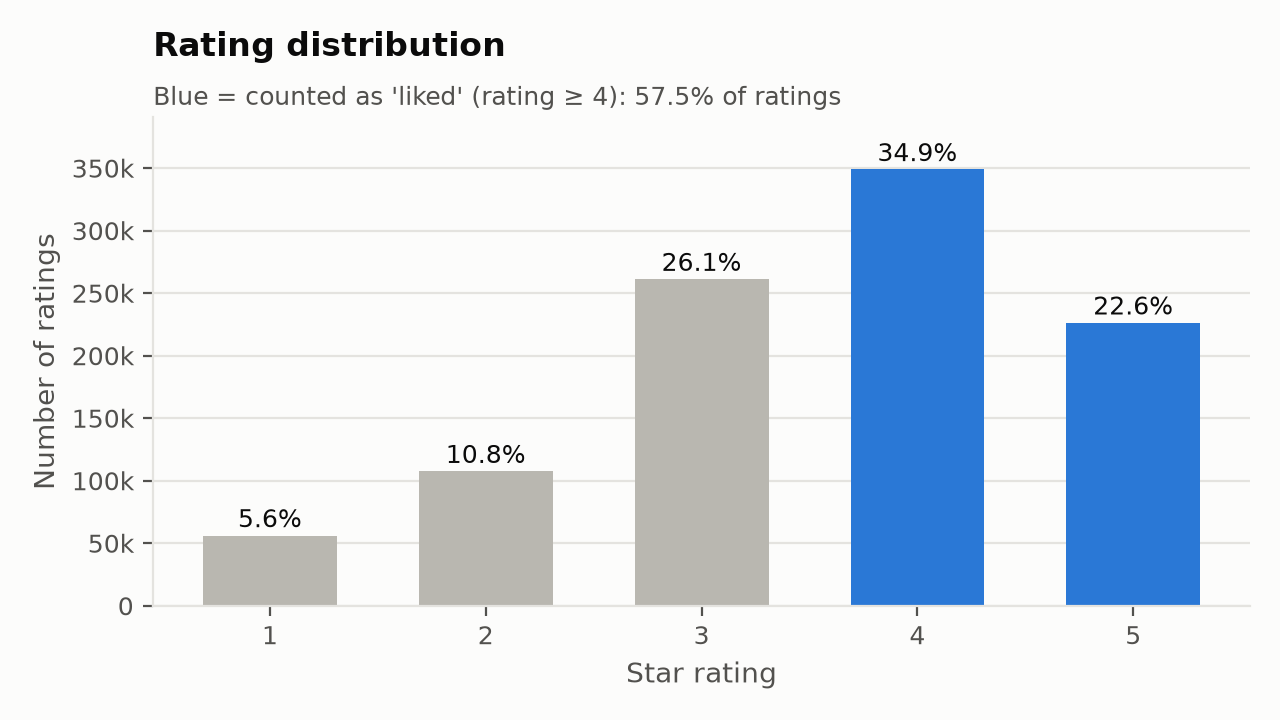

{
 "1.0": 56174,
 "2.0": 107557,
 "3.0": 261197,
 "4.0": 348971,
 "5.0": 226310
}
liked (>=4): 575,281 = 57.5%
users with < 10 liked movies: 90
users with <  3 liked movies: 5


In [3]:
show("rating_distribution")
print(json.dumps(stats["rating_counts"], indent=1))
print(f"liked (>=4): {stats['n_positive']:,} = {stats['positive_share']:.1%}")
print(f"users with < 10 liked movies: {stats['users_with_lt_10_positives']}")
print(f"users with <  3 liked movies: {stats['users_with_lt_3_positives']}")

**Finding.** Ratings lean positive (mean 3.58). Ratings of 4–5 make up **57.5 %**, i.e. 575,281
"liked" interactions. Only 90 users have fewer than 10 liked movies and just 5 have fewer than 3.

**Decision.** Keep the planned threshold: *rating ≥ 4 = liked* (the ablation in experiment E6 will
also try "every rating counts"). Users with fewer than 3 liked movies cannot give a train / validation
/ test item each, so they stay in **training only** and are not evaluated (5 users, 0.08 %).

## 3. Users: how active are they?

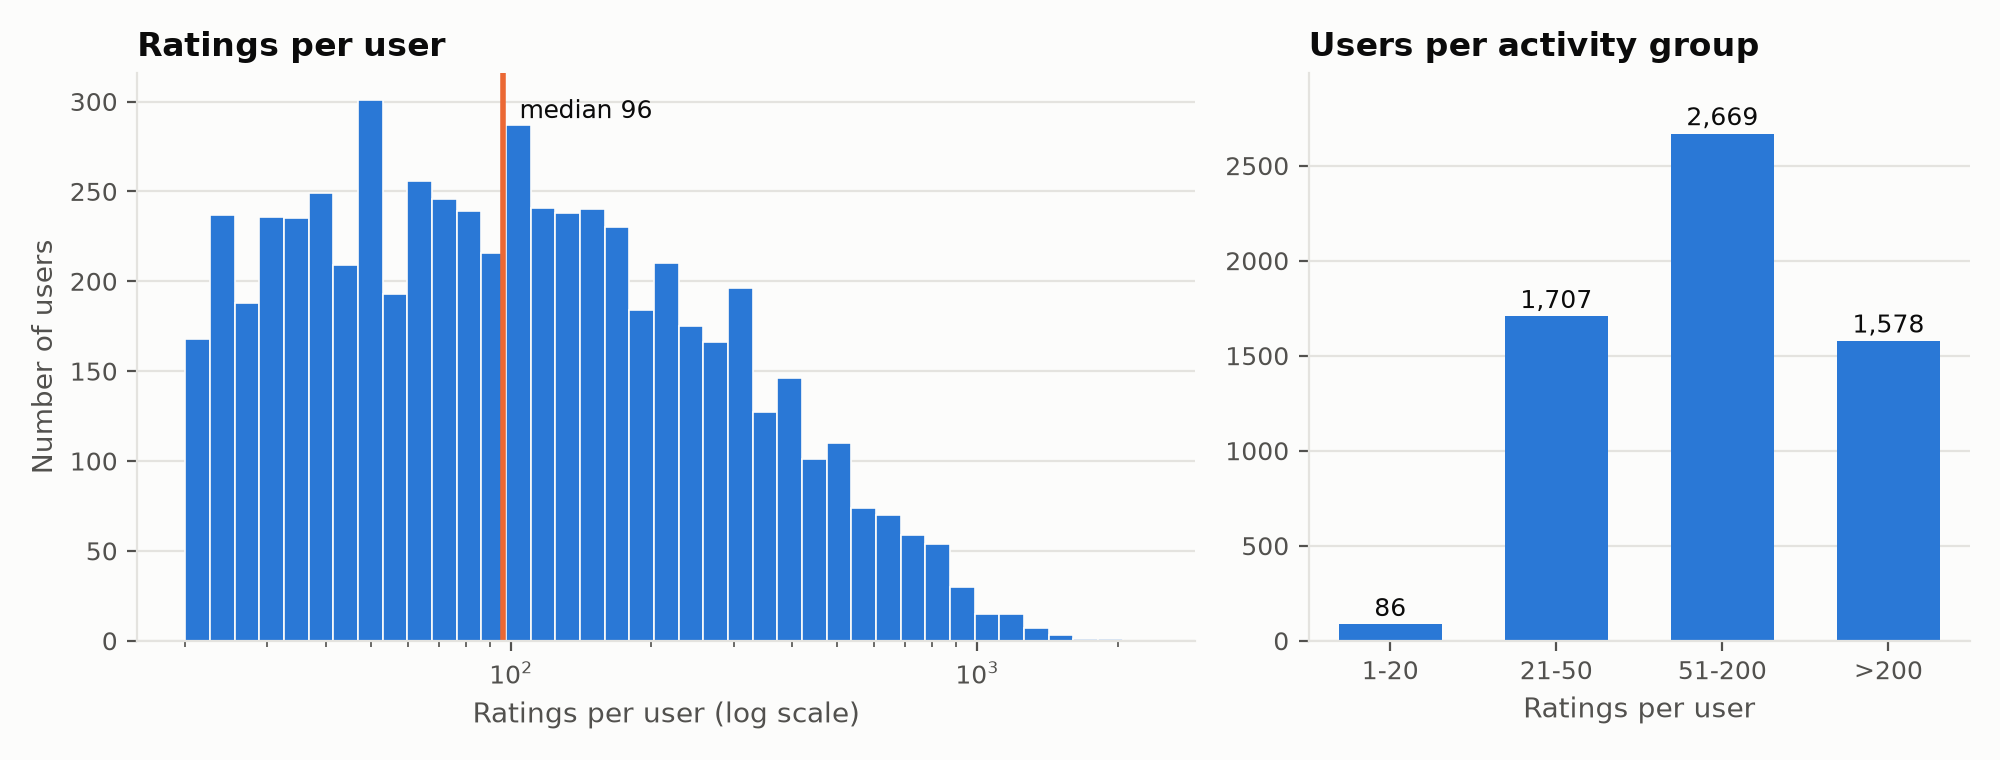

,min,p25,median,mean,p75,p90,p99,max
ratings per user,20,44.0,96.0,165.6,208.0,400.0,906.7,2314


In [4]:
show("user_activity")
pd.DataFrame([stats["user_activity"]], index=["ratings per user"])

**Finding.** Every user has at least 20 ratings (GroupLens filtered the data that way), the median
user has 96, and a few heavy users have over 2,000. The distribution is right-skewed.

**Decision.** These buckets (20 / 21–50 / 51–200 / >200) become the groups for the **cold-start
analysis (E5)**. Since nobody has fewer than 20 ratings, *true* cold start (0–5 ratings) is
simulated separately for the app's onboarding flow.

## 4. Movies: the long tail

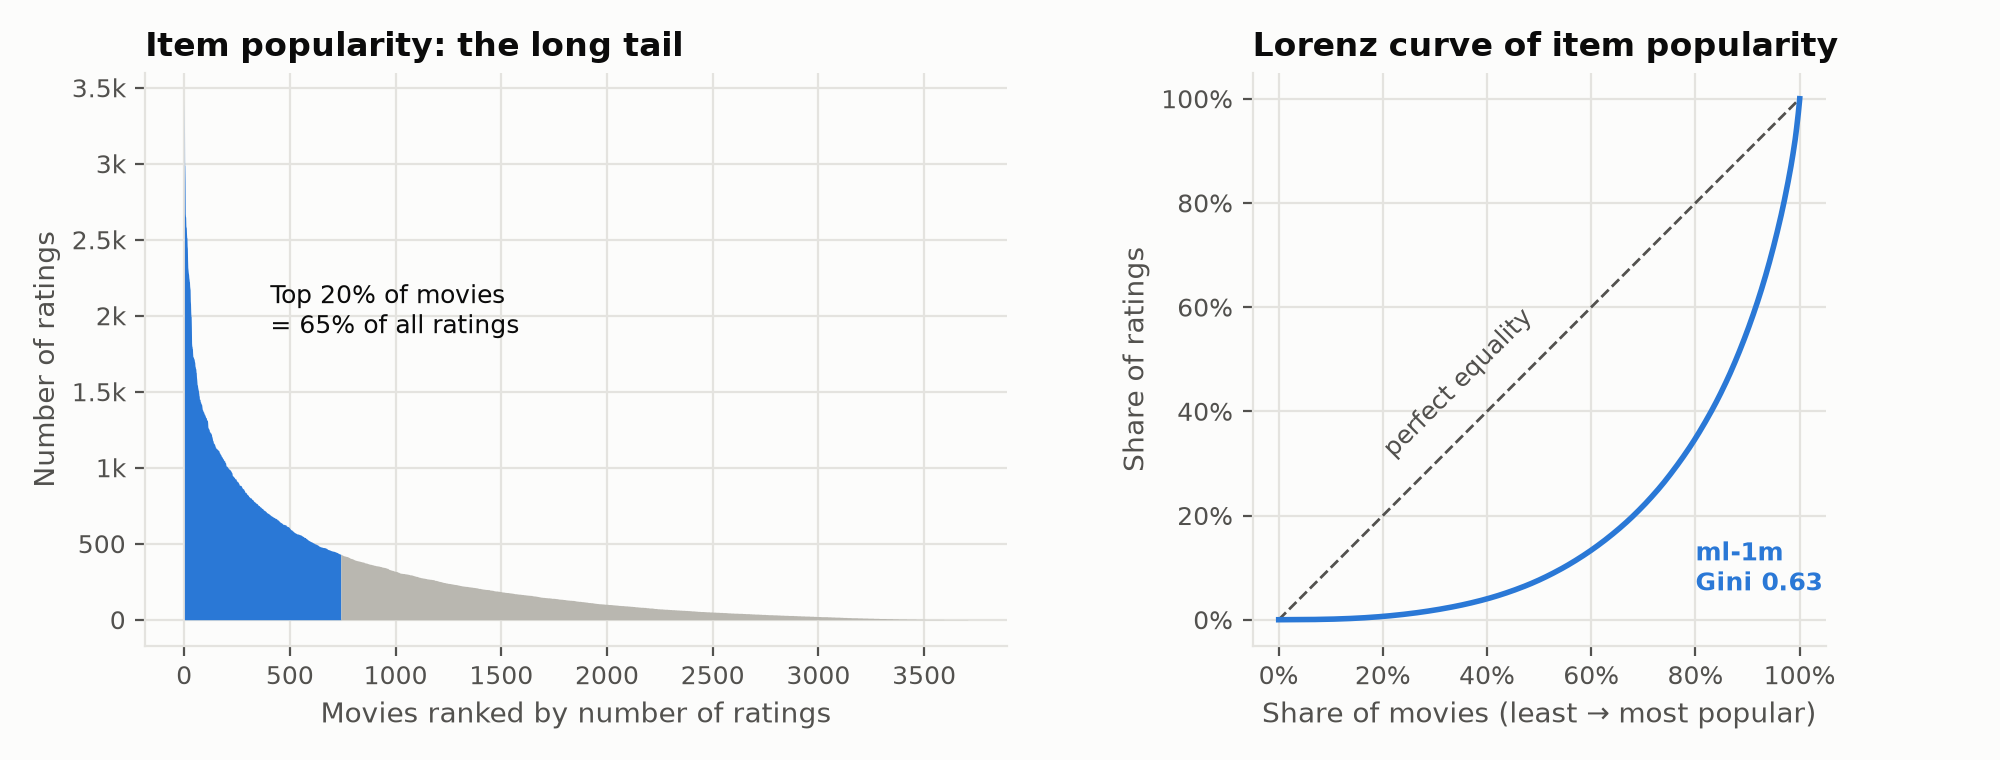

top 20% of movies get 65.2% of all ratings
Gini coefficient of movie popularity: 0.6336
movies with < 10 ratings: 446


In [5]:
show("item_long_tail")
print(f"top 20% of movies get {stats['top20pct_items_share_of_ratings']:.1%} of all ratings")
print(f"Gini coefficient of movie popularity: {stats['gini_item_popularity']}")
print(f"movies with < 10 ratings: {stats['items_with_lt_10_ratings']}")

**Finding.** Popularity is very unequal: the **top 20 % of movies receive 65 % of the ratings**
(Gini 0.63), and 446 movies have fewer than 10 ratings.

**Decision.** (1) *MostPop* will look deceptively strong on accuracy, so it is a required baseline.
(2) Accuracy alone would reward models that only push blockbusters, so we also report **coverage,
novelty and popularity bias** (experiment E4) and add a diversity step (MMR) to the hybrid.

## 5. Time: when were ratings made?

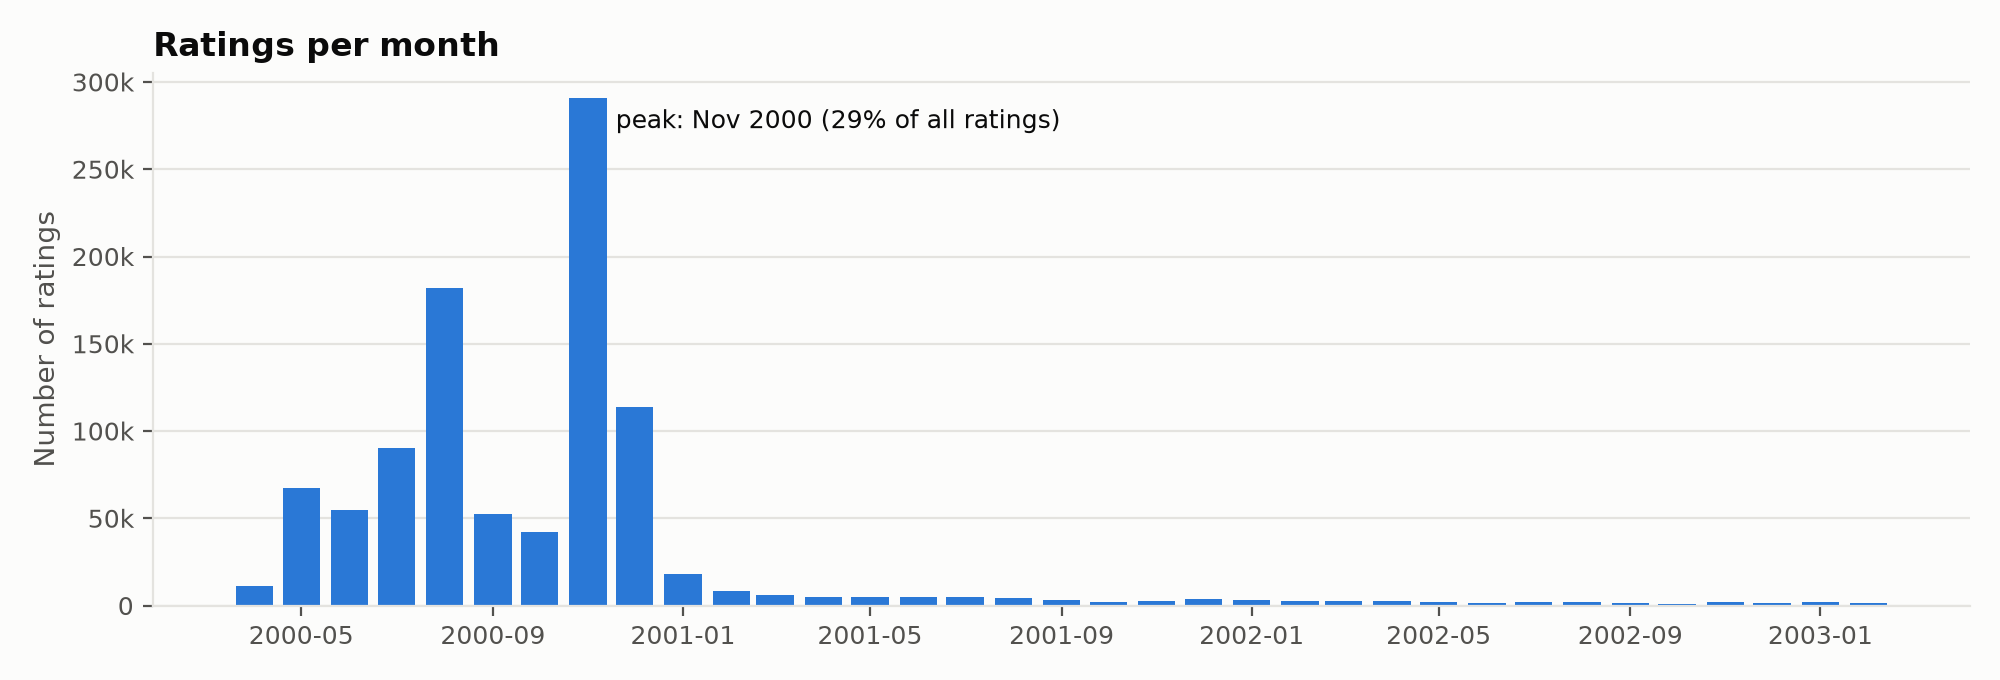

top-3 months hold 58.6% of all ratings
interactions sharing the exact same second with another of the user's: 77.4%
users who did all their rating within 1 day: 62.9%


In [6]:
show("ratings_over_time")
print(f"top-3 months hold {stats['top3_months_share_of_ratings']:.1%} of all ratings")
print(
    f"interactions sharing the exact same second with another of the user's: "
    f"{stats['tied_timestamp_share']:.1%}"
)
print(f"users who did all their rating within 1 day: {stats['users_active_within_1_day_share']:.1%}")

In [7]:
inter = ds.interactions
rows = []
for q in (0.8, 0.9):
    cut = inter["timestamp"].quantile(q)
    testable = inter.loc[inter["timestamp"] > cut, "user_id"].nunique()
    rows.append(
        {
            "global cut-off": f"{int(q * 100)}% of ratings before it",
            "date": pd.to_datetime(cut, unit="s").date(),
            "users with any test rating": f"{testable:,} / {inter['user_id'].nunique():,}",
            "share": f"{testable / inter['user_id'].nunique():.1%}",
        }
    )
pd.DataFrame(rows)

,global cut-off,date,users with any test rating,share
0,80% of ratings before it,2000-12-02,"1,783 / 6,040",29.5%
1,90% of ratings before it,2000-12-29,"1,209 / 6,040",20.0%


**Findings.**
- **58.6 %** of all ratings were made in just three months of 2000; November 2000 alone holds 29 %.
- **77 %** of ratings share the *exact same second* with another rating by the same user, and **63 %**
  of users did all their rating within a single day. MovieLens users rated movies in bulk on rating
  pages, so timestamps record *when a page was submitted*, not when a movie was watched.
- A single global cut-off date would leave only **29.5 %** of users with anything to test on.

**Decisions.**
1. Split **per user, chronologically** (each user's oldest 80 % → train, next 10 % → validation,
   newest 10 % → test) instead of using one global date. This keeps every user testable and still
   never trains on the future.
2. Break same-second ties with a **seeded random key**: the split is identical on every run and
   machine, but the order is not tied to item ids or file order. This rule matters: in Week 1 we
   measured that for **58 %** of users a train/validation/test boundary falls inside such a tie.
3. Because the order within a submitted page is arbitrary, the "watch order" SASRec learns from is
   partly artificial. We state this as a limitation, and an ablation (SASRec on real vs shuffled
   order) will measure how much order actually matters on this dataset.

## 6. Genres

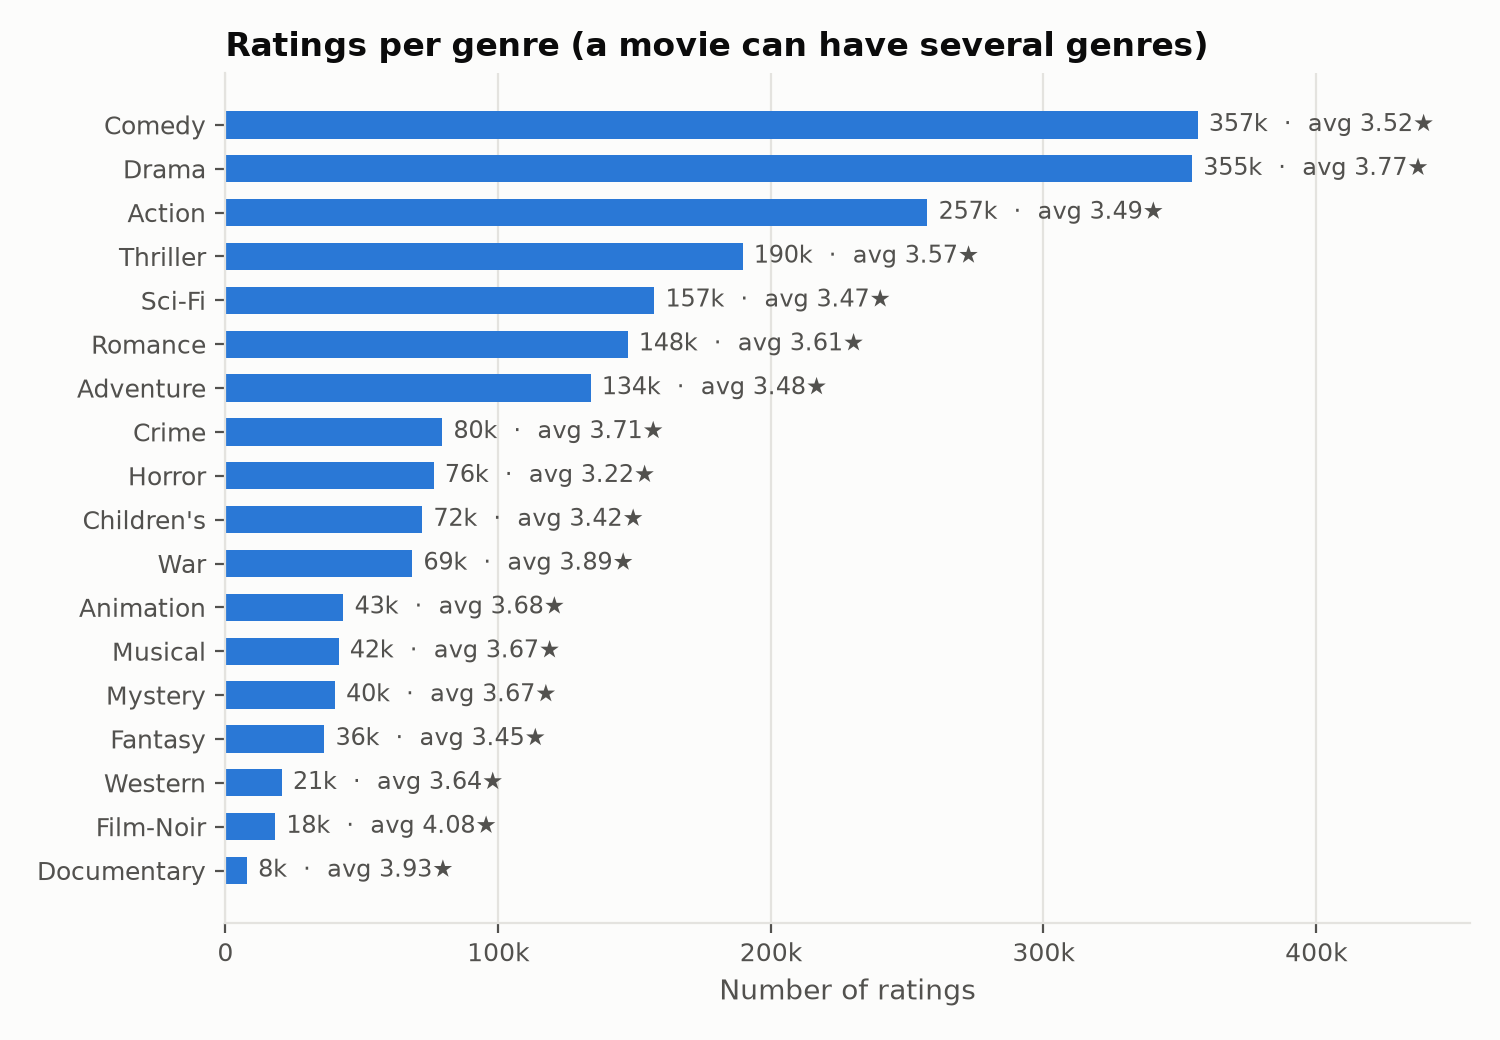

,movies,ratings,mean_rating
genre,,,
Comedy,1200,356580,3.52
Drama,1603,354529,3.77
Action,503,257457,3.49
Thriller,492,189680,3.57
Sci-Fi,276,157294,3.47
Romance,471,147523,3.61
Adventure,283,133953,3.48
Crime,211,79541,3.71
Horror,343,76386,3.22


In [8]:
show("genres")
genre_table(ds).round(2)

**Finding.** Comedy and Drama dominate (~355k ratings each). Average ratings differ by genre:
Film-Noir (4.08), Documentary (3.93) and War (3.89) are rated highest, Horror (3.22) lowest.
Niche genres are rated by fewer but more enthusiastic users.

**Decision.** Genre is a useful signal, so "how well a movie's genres match the user's taste"
becomes a **feature for the LightGBM ranker** in the hybrid model, and genre distance is used to
measure **intra-list diversity**.

## 7. Who are the users?

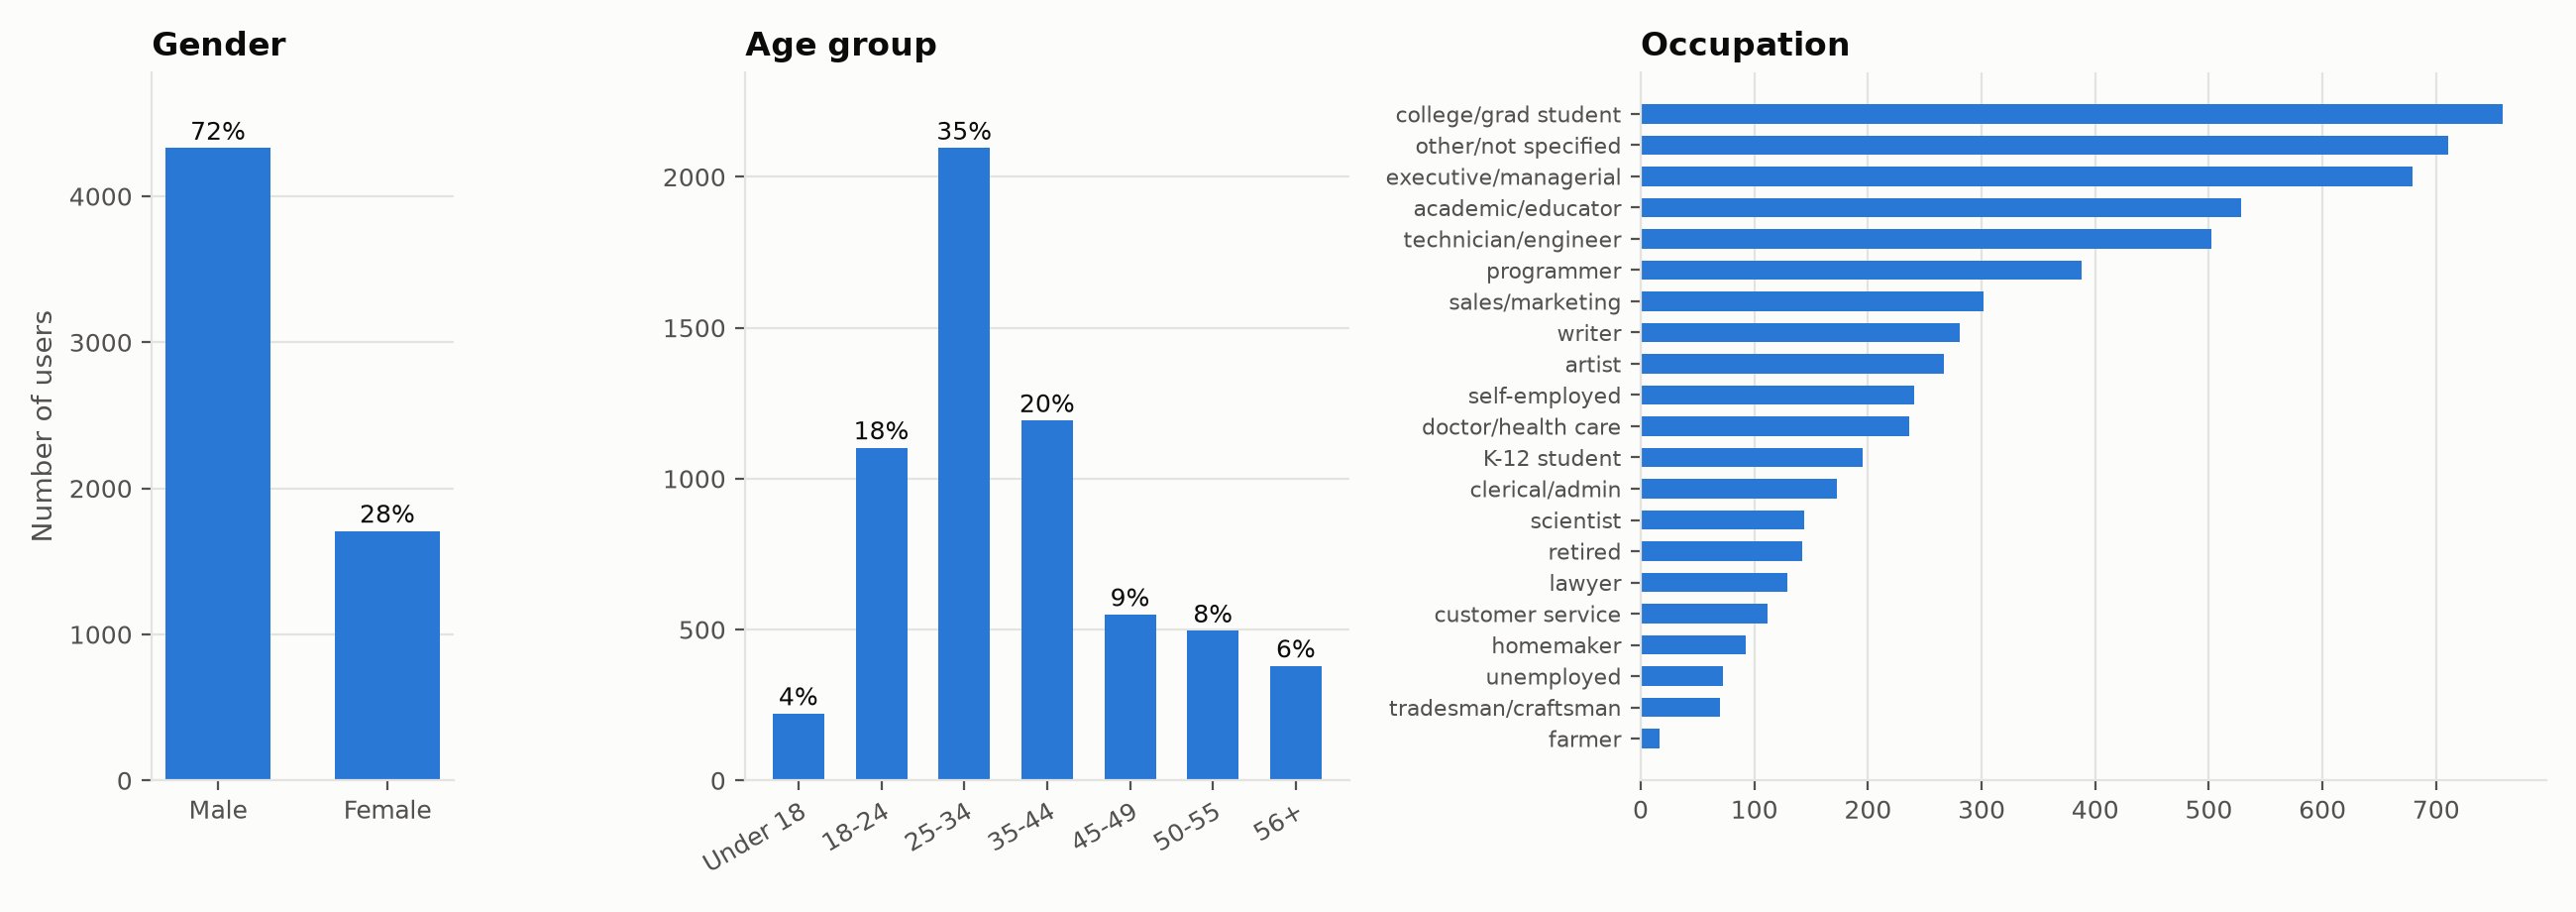

In [9]:
show("demographics")

**Finding.** 72 % of users are male, 35 % are aged 25–34, and college/grad students are the largest
occupation group. The data comes from US web users around the year 2000.

**Decision.** Demographics are available, so they become optional ranker features (and a fairness
check: does accuracy differ between groups?). The skew is a **limitation to state in the report**:
results may not transfer to other populations, which is one more reason to also test on Amazon.

## Summary: decisions carried into Week 1

| # | Decision | Driven by |
|---|---|---|
| 1 | Sparse CSR matrices everywhere | 95.5 % sparsity |
| 2 | "Liked" = rating ≥ 4; users with < 3 liked movies are train-only | rating distribution |
| 3 | Per-user chronological 80/10/10 split with a seeded random tie-break | bursty timestamps, global cut leaves 29.5 % testable |
| 4 | Report coverage, novelty and popularity bias next to accuracy | long tail, Gini 0.63 |
| 5 | Activity buckets 20 / 21–50 / 51–200 / >200 for cold-start analysis | user activity |
| 6 | Genre match and demographics as ranker features | genre and demographic tables |
| 7 | SASRec order ablation, stated as a limitation | 77 % tied timestamps |